# Martingale control variates

For the exact terminal payoff \(X=e^{-rT}g(S_T)\), subtract the discrete stochastic integral
\[
I_N=\sum_{n=0}^{N-1} h(t_n,S_{t_n})^\top \Delta B_n,\qquad
h(t,S)=e^{-rt}Z(t,S).
\]
The control sees the left-endpoint state. Each next Brownian increment has zero conditional mean, so \(\mathbb E[X-I_N]=\mathbb E[X]\) at every grid resolution. The grid changes the variance of the estimator.

The vanilla call and asymmetric five-asset geometric call have exact prices and spot deltas. The analytical control maps those deltas into independent Brownian coordinates. All grids use the same terminal payoff samples. Generate the two IID reports from the repository root.

```bash
python -m bsde_pricing martingale-control --case vanilla --output scratch/runs/martingale_vanilla.json
python -m bsde_pricing martingale-control --case geometric-five --output scratch/runs/martingale_geometric_five.json
```


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

cwd = Path.cwd()
root = cwd if (cwd / "bsde_pricing").is_dir() else cwd.parent
if not (root / "bsde_pricing").is_dir():
    raise RuntimeError("Open the notebook from the repository root or notebooks directory.")

runs = root / "scratch/runs"
report_names = ("martingale_vanilla.json", "martingale_geometric_five.json")
reports = [json.loads((runs / name).read_text(encoding="utf-8")) for name in report_names]


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join("---" for _ in headers) + " |"]
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))


show_table(
    ("Case", "Exact price", "IID paths", "Seed", "Spawn key", "Grid intervals", "Runtime"),
    [(r["case"], f'{r["reference_call_price"]:.8f}', r["n_paths"], r["seed"], r["spawn_key"],
      [g["steps"] for g in r["grids"]], r["runtime"]["system"]) for r in reports],
)


| Case | Exact price | IID paths | Seed | Spawn key | Grid intervals | Runtime |
| --- | --- | --- | --- | --- | --- | --- |
| vanilla | 9.41340338 | 16384 | 2026 | [25, 1] | [4, 8, 16, 32, 64] | macOS-27.0.1-arm64-arm-64bit |
| geometric-five | 5.49471932 | 16384 | 2026 | [25, 5] | [4, 8, 16, 32, 64] | macOS-27.0.1-arm64-arm-64bit |

## Prices and sampling uncertainty

The zero control gives ordinary IID payoff Monte Carlo. The controlled standard error is the sample standard deviation of \(X-I_N\) divided by \(\sqrt M\). The variance reduction factor divides the zero-control sample variance by the controlled sample variance. The intervals are pointwise normal approximations. Reusing terminal paths makes the rows within a case dependent.

In [2]:
price_rows = []
for report in reports:
    controls = [("Zero", report["zero_control"], 1.0)]
    controls.extend((g["steps"], g["analytical_control"], g["variance_reduction_factor"])
                    for g in report["grids"])
    for steps, estimate, factor in controls:
        low, high = estimate["confidence_low"], estimate["confidence_high"]
        interval = "unavailable" if low is None else f"[{low:.6f}, {high:.6f}]"
        z = estimate["error_in_standard_errors"]
        price_rows.append((report["case"], steps, f'{estimate["estimate"]:.6f}',
                           f'{estimate["standard_error"]:.6f}', interval,
                           "unavailable" if z is None else f"{z:+.2f}",
                           "unavailable" if factor is None else f"{factor:.2f}"))

show_table(("Case", "Control intervals", "Price", "SE", "95% interval", "Error / SE", "Variance factor"),
           price_rows)


| Case | Control intervals | Price | SE | 95% interval | Error / SE | Variance factor |
| --- | --- | --- | --- | --- | --- | --- |
| vanilla | Zero | 9.435808 | 0.109651 | [9.220896, 9.650719] | +0.20 | 1.00 |
| vanilla | 4 | 9.423608 | 0.030638 | [9.363558, 9.483657] | +0.33 | 12.81 |
| vanilla | 8 | 9.408532 | 0.021856 | [9.365696, 9.451368] | -0.22 | 25.17 |
| vanilla | 16 | 9.407855 | 0.015747 | [9.376992, 9.438718] | -0.35 | 48.49 |
| vanilla | 32 | 9.406622 | 0.011248 | [9.384576, 9.428668] | -0.60 | 95.03 |
| vanilla | 64 | 9.417803 | 0.008000 | [9.402124, 9.433482] | +0.55 | 187.88 |
| geometric-five | Zero | 5.459020 | 0.067483 | [5.326756, 5.591284] | -0.53 | 1.00 |
| geometric-five | 4 | 5.517769 | 0.019937 | [5.478693, 5.556846] | +1.16 | 11.46 |
| geometric-five | 8 | 5.524709 | 0.014559 | [5.496175, 5.553243] | +2.06 | 21.49 |
| geometric-five | 16 | 5.509509 | 0.010317 | [5.489288, 5.529730] | +1.43 | 42.78 |
| geometric-five | 32 | 5.503657 | 0.007317 | [5.489316, 5.517998] | +1.22 | 85.06 |
| geometric-five | 64 | 5.500169 | 0.005240 | [5.489899, 5.510439] | +1.04 | 165.85 |

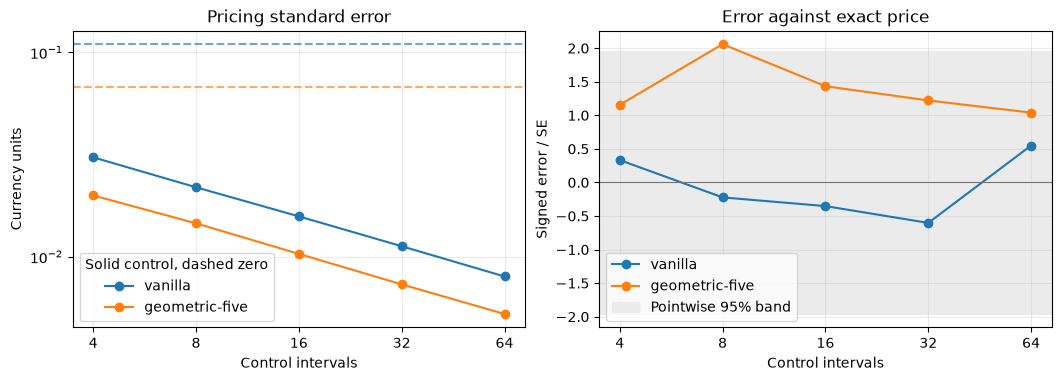

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), constrained_layout=True)
for report, color in zip(reports, ("tab:blue", "tab:orange")):
    grids = report["grids"]
    steps = [g["steps"] for g in grids]
    axes[0].plot(steps, [g["analytical_control"]["standard_error"] for g in grids],
                 "o-", color=color, label=report["case"])
    axes[0].axhline(report["zero_control"]["standard_error"], color=color, ls="--", alpha=0.65)
    axes[1].plot(steps, [g["analytical_control"]["error_in_standard_errors"] for g in grids],
                 "o-", color=color, label=report["case"])

axes[0].set(title="Pricing standard error", yscale="log", ylabel="Currency units")
axes[0].legend(title="Solid control, dashed zero")
axes[1].axhspan(-1.96, 1.96, color="0.92", label="Pointwise 95% band")
axes[1].axhline(0, color="0.45", lw=0.8)
axes[1].set(title="Error against exact price", ylabel="Signed error / SE")
axes[1].legend()
for axis in axes:
    axis.set(xscale="log", xlabel="Control intervals")
    axis.set_xticks(steps, labels=steps)
    axis.minorticks_off()
    axis.grid(alpha=0.25)
plt.show()


## Martingale checks

Itô isometry gives \(\mathbb E[I_N^2]=\mathbb E[Q_N]\) for \(Q_N=\sum_n \|h(t_n,S_{t_n})\|^2\Delta t\). The uncertainty of the isometry gap uses paired path observations \(I_N^2-Q_N\). The stochastic-integral mean and the isometry gap each have target zero.

In [4]:
show_table(
    ("Case", "Intervals", "Mean integral", "Mean / SE", "Mean squared integral",
     "Mean control energy", "Isometry gap", "Gap / SE"),
    [(r["case"], g["steps"], f'{g["stochastic_integral"]["estimate"]:+.5f}',
      f'{g["stochastic_integral"]["mean_in_standard_errors"]:+.2f}',
      f'{g["mean_squared_integral"]:.5f}', f'{g["mean_integrated_squared_control"]:.5f}',
      f'{g["isometry_gap"]["estimate"]:+.5f}', f'{g["isometry_gap"]["mean_in_standard_errors"]:+.2f}')
     for r in reports for g in r["grids"]],
)


| Case | Intervals | Mean integral | Mean / SE | Mean squared integral | Mean control energy | Isometry gap | Gap / SE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| vanilla | 4 | +0.01220 | +0.12 | 182.15574 | 184.06304 | -1.90730 | -0.71 |
| vanilla | 8 | +0.02728 | +0.25 | 189.25482 | 191.50480 | -2.24999 | -0.75 |
| vanilla | 16 | +0.02795 | +0.26 | 193.07029 | 195.26242 | -2.19213 | -0.70 |
| vanilla | 32 | +0.02919 | +0.27 | 194.97308 | 197.19585 | -2.22276 | -0.69 |
| vanilla | 64 | +0.01800 | +0.16 | 195.97239 | 198.21912 | -2.24672 | -0.69 |
| geometric-five | 4 | -0.05875 | -0.91 | 68.51836 | 69.59098 | -1.07262 | -1.03 |
| geometric-five | 8 | -0.06569 | -0.99 | 71.61595 | 72.74953 | -1.13358 | -0.99 |
| geometric-five | 16 | -0.05049 | -0.76 | 73.21950 | 74.41059 | -1.19109 | -0.99 |
| geometric-five | 32 | -0.04464 | -0.66 | 73.81774 | 75.24432 | -1.42658 | -1.16 |
| geometric-five | 64 | -0.04115 | -0.61 | 74.26509 | 75.67676 | -1.41167 | -1.14 |

The 64-interval analytical control substantially reduces sampling error in both cases. The geometric-basket estimate at eight intervals lies 2.06 standard errors above the exact price. The other pointwise intervals cover their references in this development run. The variance factors describe equal path counts. Computing the control requires intermediate states and deltas, so an equal-cost comparison is a separate experiment.

## Frozen learned controls on the arithmetic basket

On each antithetic pair, write \(X\) for the mean discounted payoff and \(I\) for the mean discounted stochastic integral. The adjusted observation is \(X-\beta I\). With the network frozen, \(\mathbb E[I]=0\) by predictability. A coefficient fitted on independent pairs is fixed conditional on that pilot, so the evaluation mean still targets the model price. The optimal population coefficient for this sampling unit is \(\operatorname{Cov}(X,I)/\operatorname{Var}(I)\).

The value-gradient network supplies spot deltas, which are mapped to Brownian coordinates and discounted. The terminal-loss network supplies discounted Brownian controls directly on its training grid. The analytical geometric-basket control is a proxy for the arithmetic payoff. The two conventional methods use the geometric terminal payoff with known mean.

Generate the report using the saved validation-selected arithmetic pilot checkpoints.

```bash
python -m bsde_pricing learned-control --output scratch/runs/martingale_learned.json
```


In [5]:
learned = json.loads((runs / "martingale_learned.json").read_text(encoding="utf-8"))
reference = learned["reference_price"]
show_table(
    ("Case", "Evaluation states per method", "Control intervals", "Reference price", "Reference SE"),
    [(learned["case"]["name"], learned["evaluation_states_per_method"], learned["steps"],
      f'{reference["estimate"]:.8f}', f'{reference["standard_error"]:.8f}')],
)
show_table(
    ("Checkpoint", "Selected update", "Completed updates", "Training seconds"),
    [(kind, c["selected_step"], c["completed_updates"], f'{c["training_seconds"]:.3f}')
     for kind, c in learned["checkpoints"].items()],
)


| Case | Evaluation states per method | Control intervals | Reference price | Reference SE |
| --- | --- | --- | --- | --- |
| arithmetic-10 | 8192 | 16 | 6.40618406 | 0.00016980 |

| Checkpoint | Selected update | Completed updates | Training seconds |
| --- | --- | --- | --- |
| terminal_loss | 2900 | 3000 | 17.139 |
| value_gradient | 3000 | 3000 | 8.919 |

Each method evaluates 8,192 terminal states. Antithetic uncertainty uses 4,096 pair means. Sobol uncertainty uses 16 independent scramble means of 512 points each. Variance factors divide the plain antithetic estimator variance by the reported estimator variance. The timing scope is recorded per method, with coefficient-pilot work included for fitted methods. Training and checkpoint setup are tracked separately.

In [6]:
method_names = {
    "plain_antithetic": "Plain antithetic",
    "analytical_geometric_proxy_unit": "Geometric integral proxy",
    "value_gradient_unit": "Value-gradient unit",
    "value_gradient_fitted": "Value-gradient fitted",
    "terminal_loss_unit": "Terminal-loss unit",
    "terminal_loss_fitted": "Terminal-loss fitted",
    "antithetic_geometric_control": "Antithetic geometric payoff",
    "scrambled_sobol_geometric_control": "Sobol geometric payoff",
}
learned_rows = [learned["methods"][key] for key in method_names]
show_table(
    ("Method", "Coefficient", "Price", "SE", "95% interval", "Variance factor", "Measured seconds"),
    [(name, f'{row["coefficient"]:.5f}', f'{row["price"]["estimate"]:.6f}',
      f'{row["price"]["standard_error"]:.6f}',
      f'[{row["price"]["confidence_low"]:.6f}, {row["price"]["confidence_high"]:.6f}]',
      f'{row["variance_reduction_factor"]:.2f}', f'{row["measured_seconds"]:.3f}')
     for name, row in zip(method_names.values(), learned_rows)],
)


| Method | Coefficient | Price | SE | 95% interval | Variance factor | Measured seconds |
| --- | --- | --- | --- | --- | --- | --- |
| Plain antithetic | 0.00000 | 6.403511 | 0.063823 | [6.278421, 6.528601] | 1.00 | 0.009 |
| Geometric integral proxy | 1.00000 | 6.419222 | 0.018043 | [6.383860, 6.454585] | 12.51 | 0.132 |
| Value-gradient unit | 1.00000 | 6.413936 | 0.025944 | [6.363088, 6.464785] | 6.05 | 0.266 |
| Value-gradient fitted | 1.29263 | 6.416987 | 0.022489 | [6.372909, 6.461065] | 8.05 | 0.572 |
| Terminal-loss unit | 1.00000 | 6.398313 | 0.023986 | [6.351301, 6.445326] | 7.08 | 0.127 |
| Terminal-loss fitted | 1.02319 | 6.398193 | 0.023991 | [6.351171, 6.445215] | 7.08 | 0.253 |
| Antithetic geometric payoff | 0.99202 | 6.408360 | 0.006729 | [6.395172, 6.421549] | 89.96 | 0.007 |
| Sobol geometric payoff | 0.99312 | 6.410675 | 0.002803 | [6.404699, 6.416650] | 518.26 | 0.029 |

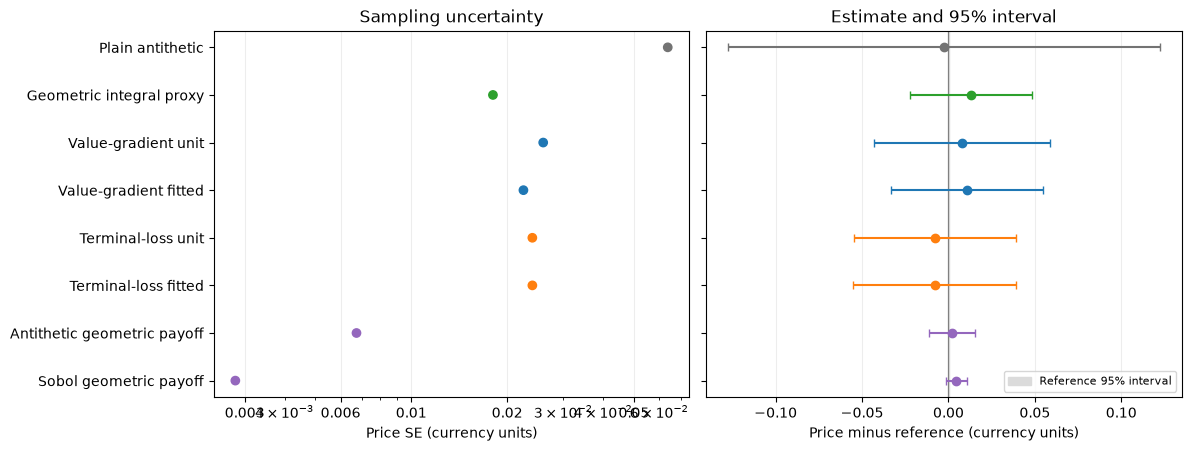

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.4), sharey=True, constrained_layout=True)
positions = list(range(len(learned_rows)))
colors = ["0.45", "tab:green", "tab:blue", "tab:blue", "tab:orange",
          "tab:orange", "tab:purple", "tab:purple"]
prices = [row["price"] for row in learned_rows]
axes[0].scatter([p["standard_error"] for p in prices], positions, c=colors)
axes[0].set(xscale="log", xlabel="Price SE (currency units)", title="Sampling uncertainty")
axes[0].set_xticks([0.003, 0.006, 0.01, 0.02, 0.05], labels=["0.003", "0.006", "0.01", "0.02", "0.05"])
axes[0].set_yticks(positions, labels=list(method_names.values()))
axes[0].invert_yaxis()
reference_price = reference["estimate"]
axes[1].axvspan(reference["confidence_low"]-reference_price,
                reference["confidence_high"]-reference_price, color="0.86", label="Reference 95% interval")
axes[1].axvline(0, color="0.5", lw=0.8)
for i, (price, color) in enumerate(zip(prices, colors)):
    mean = price["estimate"]
    axes[1].errorbar(mean-reference_price, i,
                     xerr=[[mean-price["confidence_low"]], [price["confidence_high"]-mean]],
                     fmt="o", capsize=3, color=color)
axes[1].set(xlabel="Price minus reference (currency units)", title="Estimate and 95% interval")
axes[1].legend(loc="lower right", fontsize=8)
for axis in axes:
    axis.grid(axis="x", alpha=0.22)
plt.show()


On this development allocation, coefficient fitting improves the value-gradient estimate's sampling variance and slightly increases the terminal-loss estimate's variance relative to its unit-coefficient run. Both conventional geometric payoff controls deliver lower standard errors than the learned controls. The matched-precision comparison uses repeated allocations and accounts for training, pilot and evaluation costs.